# 07 Do style matchups predict outcomes beyond Elo?

Leak-free, time-split evaluation (`src/elo.py`, `src/matchups.py`, `docs/matchups.md`):

- **Elo:** fight-by-fight ratings from all UFC fights since 1994, with settings chosen on 2005–2018 fights only. The main analysis
  uses the **improved Elo** (section 1b). The baseline Elo (constant K = 80) is kept for comparison.
- **Style axes:** fitted on profiles built **as of 2019-01-01** and frozen, aligned to the four named axes. For every fight, both
  fighters' profiles are built as of the fight date (earlier fights only) and transformed with that frozen model.
- **Train:** decisive fights 2006–2018. **Test:** decisive fights from 2019-01-01 to 2026-08-08. Inclusion: both fighters have ≥ 3 prior
  UFC fights since 2000 (≥ 5 also reported). Draws and no contests are excluded from the outcome models.
- **Models** (logistic, no intercept, antisymmetric features, so P(A beats B) = 1 − P(B beats A)):
  1. Elo difference
  2. + differences in the four axis scores
  3. + the six antisymmetric interactions a_i·b_j − a_j·b_i
- **Regularization:** L2 on the style terms only, never on Elo. The penalty on the axis differences is tuned for model 2. Model 3 keeps
  that and tunes a separate penalty on the interactions. Tuning uses time-based validation inside the training period (fit on 2006–15,
  validate on 2016–18).

**Rule:** an effect is claimed only if it holds up on the 2019+ test set.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import elo
import features as F
import matchups as M
import style_axes as A

pd.set_option("display.width", 220, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
NAMES = {f"d_{k}": f"Δ {v}" for k, v in A.AXIS_NAMES.items()}
NAMES.update({f"x_{M.AXES[i]}_{M.AXES[j]}": f"{A.AXIS_NAMES[M.AXES[i]]} × {A.AXIS_NAMES[M.AXES[j]]}" for i, j in M.PAIRS})
NAMES["elo_diff"] = "Elo difference (per 100 points)"
data = M.build_dataset()
print(data.groupby("set").agg(fights=("y", "size"), first=("event_date", "min"), last=("event_date", "max")))

       fights       first        last
set                                  
test     3047  2019-01-19  2026-08-08
train    3172  2006-01-16  2018-12-29


## 1. Elo: choosing K on pre-test fights (baseline Elo)

k,8,12,16,20,24,28,32,40,48,56,64,80,96,128
log_loss,0.6896,0.6881,0.6868,0.6856,0.6845,0.6836,0.6827,0.6813,0.6802,0.6793,0.6788,0.6782,0.6785,0.6813
brier,0.2482,0.2475,0.2468,0.2463,0.2457,0.2453,0.2449,0.2442,0.2436,0.2432,0.2429,0.2426,0.2427,0.2436
fights,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000,4430.0000


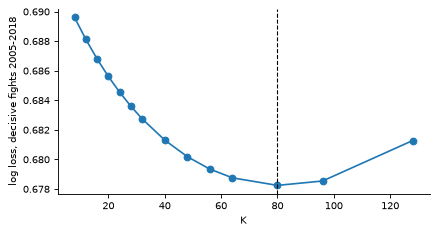

baseline K = 80 (minimum of the grid; flat from 64 to 96). Coin-flip log loss = 0.6931.


In [2]:
kt = elo.tune_k(elo.load_ufc_fights())
display(kt.round(4).T)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(kt.index, kt["log_loss"], marker="o"); ax.axvline(elo.ELO_K, color="k", ls="--", lw=1)
ax.set_xlabel("K"); ax.set_ylabel("log loss, decisive fights 2005-2018"); plt.show()
print(f"baseline K = {elo.ELO_K:g} (minimum of the grid; flat from 64 to 96). Coin-flip log loss = {np.log(2):.4f}.")

### 1b. Improved Elo (settings chosen on 2005–2018 fights only)

Three refinements, each tuned on its own with K retuned, then all three together (`elo.tune_variants`, grid in `elo.VARIANT_GRID`):

- **Debut rating relative to the roster.** A newcomer starts at the mean rating of fighters active in the past 2 years, minus an
  offset. A lower *fixed* starting rating would change nothing in zero-sum Elo: everyone debuts at it, so all ratings shift together.
- **Larger updates for finishes.** KO/TKO, submission or doctor's stoppage wins update by K × multiplier; decisions, DQs and draws by K.
- **K shrinking with experience.** Each fighter's K is k × (prior UFC fights + 1)^−decay.

The grid search takes about 40 minutes, so its results are read from the committed table `docs/elo_tuning.csv`
(`python src/elo.py --tune` reruns the search and rewrites it). A blank `debut_offset` means the fixed starting rating.

In [3]:
variants = pd.read_csv(elo.TUNING_PATH, index_col=0)
variants["Δ vs baseline"] = variants["log_loss"] - variants["log_loss"].iloc[0]
display(variants.round(5))
print("chosen ELO_PARAMS:", elo.ELO_PARAMS)
f_all = elo.load_ufc_fights()
for name, params in [("baseline K=80", {"k": elo.ELO_K}), ("improved", elo.ELO_PARAMS)]:
    r = elo.run_elo(f_all, **params)
    w = r[r["result_status"] == "win"]
    for lo, hi in [("2005-01-01", "2019-01-01"), ("2019-01-01", "2027-01-01")]:
        ww = w[(w["event_date"] >= lo) & (w["event_date"] < hi)]
        print(f"{name:14s} {lo[:4]}-{int(hi[:4]) - 1}: log loss {elo.log_loss(ww['exp_red'].to_numpy(), ww['red_score'].to_numpy()):.4f}, "
              f"favourite wins {np.mean((ww['exp_red'] > 0.5) == (ww['red_score'] == 1)):.3f}  ({len(ww):,} fights)")
print("(2019+ is out of sample for the Elo settings)")

,log_loss,k,debut_offset,finish_mult,k_decay,Δ vs baseline
variant,,,,,,
"baseline (constant K, fixed start)",0.6782,80,NaN,1.00,0.0,0.0000
+ debut rating relative to roster,0.6761,80,0.0,1.00,0.0,-0.0022
+ larger updates for finishes,0.6781,80,NaN,1.25,0.0,-0.0002
+ K shrinking with experience,0.6776,100,NaN,1.00,0.2,-0.0007
all three combined,0.6750,100,0.0,1.25,0.2,-0.0032


chosen ELO_PARAMS: {'k': 100.0, 'debut_offset': 0.0, 'finish_mult': 1.25, 'k_decay': 0.2}


baseline K=80  2005-2018: log loss 0.6782, favourite wins 0.553  (4,430 fights)
baseline K=80  2019-2026: log loss 0.6827, favourite wins 0.556  (3,804 fights)


improved       2005-2018: log loss 0.6750, favourite wins 0.563  (4,430 fights)
improved       2019-2026: log loss 0.6697, favourite wins 0.580  (3,804 fights)
(2019+ is out of sample for the Elo settings)


## 2. The frozen 2019 style axes

Loadings of the axes fitted on profiles as of 2019-01-01, and their congruence with the full-data axes in `docs/style_axes.md`.

In [4]:
ax19 = M.frozen_axes()
full = A.StyleAxes.load(A.MODEL_DIR / "style_axes_m4.joblib")
display(ax19.loadings.rename(columns=A.AXIS_NAMES).round(2))
cong = [float(full.loadings.iloc[:, j] @ ax19.loadings.iloc[:, j] / np.linalg.norm(full.loadings.iloc[:, j]) / np.linalg.norm(ax19.loadings.iloc[:, j])) for j in range(4)]
print("fitted on", ax19.metadata["n_fighters"], "eligible fighters as of 2019-01-01; congruence with full-data axes:",
      dict(zip(A.AXIS_NAMES.values(), np.round(cong, 3))))

,grappler vs. volume striker,clinch and body work,submission hunting,leg kicking
pos_clinch,0.25,0.77,0.01,0.05
pos_ground,0.77,0.07,0.25,-0.07
tgt_body,-0.12,0.85,0.03,0.11
tgt_leg,-0.07,0.09,-0.07,0.95
td_att_per15,0.85,-0.08,-0.00,-0.00
ctrl_share,0.93,0.08,0.10,-0.06
sub_att_per15,0.07,0.00,0.88,-0.15
pace,-0.44,-0.12,-0.57,-0.32


fitted on 706 eligible fighters as of 2019-01-01; congruence with full-data axes: {'grappler vs. volume striker': np.float64(0.997), 'clinch and body work': np.float64(0.997), 'submission hunting': np.float64(0.992), 'leg kicking': np.float64(0.989)}


## 3. Model comparison on the 2019+ test set (improved Elo)

In [5]:
res = {mp: M.evaluate(data, mp, n_boot=2000) for mp in (3, 5)}
for mp, r in res.items():
    print(f"\n=== both fighters with >= {mp} prior UFC fights: train {r['n_train']:,} fights, test {r['n_test']:,} fights ===")
    m = r["metrics"].copy()
    m["log loss [95% CI]"] = [f"{a:.4f} [{b:.4f}, {c:.4f}]" for a, b, c in zip(m.log_loss, m.ll_lo, m.ll_hi)]
    m["Brier [95% CI]"] = [f"{a:.4f} [{b:.4f}, {c:.4f}]" for a, b, c in zip(m.brier, m.brier_lo, m.brier_hi)]
    display(m[["log loss [95% CI]", "Brier [95% CI]", "accuracy"]])
    v = r["vs_elo"].copy()
    v["Δ log loss vs Elo [95% CI]"] = [f"{a:+.4f} [{b:+.4f}, {c:+.4f}]" for a, b, c in zip(v.d_log_loss, v.dll_lo, v.dll_hi)]
    v["Δ Brier vs Elo [95% CI]"] = [f"{a:+.4f} [{b:+.4f}, {c:+.4f}]" for a, b, c in zip(v.d_brier, v.dbr_lo, v.dbr_hi)]
    v["P(better than Elo)"] = v["p_better"].round(3)
    display(v[["Δ log loss vs Elo [95% CI]", "Δ Brier vs Elo [95% CI]", "P(better than Elo)"]])
    print("chosen penalties:", {k: f["lambda"] for k, f in r["fits"].items()},
          "| max |P(A>B) + P(B>A) - 1| after swapping fighters:", max(f["max_swap_error"] for f in r["fits"].values()))


=== both fighters with >= 3 prior UFC fights: train 1,772 fights, test 2,015 fights ===


,log loss [95% CI],Brier [95% CI],accuracy
model,,,
elo,"0.6685 [0.6608, 0.6759]","0.2380 [0.2342, 0.2416]",0.5891
elo+style,"0.6677 [0.6596, 0.6755]","0.2376 [0.2337, 0.2414]",0.5772
elo+inter,"0.6677 [0.6596, 0.6755]","0.2376 [0.2337, 0.2414]",0.5772
raw_elo,"0.6671 [0.6574, 0.6763]","0.2374 [0.2328, 0.2418]",0.5891


,Δ log loss vs Elo [95% CI],Δ Brier vs Elo [95% CI],P(better than Elo)
model,,,
elo+style,"-0.0009 [-0.0039, +0.0021]","-0.0004 [-0.0018, +0.0011]",0.714
elo+inter,"-0.0009 [-0.0039, +0.0021]","-0.0004 [-0.0018, +0.0011]",0.714


chosen penalties: {'elo': 0.0, 'elo+style': 30.0, 'elo+inter': 100000.0} | max |P(A>B) + P(B>A) - 1| after swapping fighters: 2.220446049250313e-16

=== both fighters with >= 5 prior UFC fights: train 1,074 fights, test 1,392 fights ===


,log loss [95% CI],Brier [95% CI],accuracy
model,,,
elo,"0.6656 [0.6561, 0.6750]","0.2366 [0.2321, 0.2412]",0.5891
elo+style,"0.6679 [0.6580, 0.6776]","0.2378 [0.2329, 0.2425]",0.5898
elo+inter,"0.6679 [0.6580, 0.6776]","0.2378 [0.2330, 0.2425]",0.5891
raw_elo,"0.6645 [0.6538, 0.6752]","0.2362 [0.2311, 0.2413]",0.5891


,Δ log loss vs Elo [95% CI],Δ Brier vs Elo [95% CI],P(better than Elo)
model,,,
elo+style,"+0.0023 [-0.0024, +0.0067]","+0.0011 [-0.0012, +0.0033]",0.155
elo+inter,"+0.0023 [-0.0024, +0.0067]","+0.0011 [-0.0012, +0.0033]",0.154


chosen penalties: {'elo': 0.0, 'elo+style': 0.0, 'elo+inter': 100000.0} | max |P(A>B) + P(B>A) - 1| after swapping fighters: 2.220446049250313e-16


In [6]:
print("Same comparison with the baseline (K = 80) Elo, as in the previous version:")
res_base = {mp: M.evaluate(data, mp, n_boot=2000, elo_col="elo_base") for mp in (3, 5)}
rows = []
for mp in (3, 5):
    for which, rr in (("improved Elo", res[mp]), ("baseline Elo", res_base[mp])):
        for m in ["elo+style", "elo+inter"]:
            v = rr["vs_elo"].loc[m]
            rows.append({"prior fights": f">= {mp}", "Elo": which, "model": m,
                         "Elo-only test log loss": round(rr["metrics"].loc["elo", "log_loss"], 4),
                         "Δ log loss vs Elo [95% CI]": f"{v.d_log_loss:+.4f} [{v.dll_lo:+.4f}, {v.dll_hi:+.4f}]",
                         "Δ Brier [95% CI]": f"{v.d_brier:+.4f} [{v.dbr_lo:+.4f}, {v.dbr_hi:+.4f}]"})
display(pd.DataFrame(rows))

Same comparison with the baseline (K = 80) Elo, as in the previous version:


,prior fights,Elo,model,Elo-only test log loss,Δ log loss vs Elo [95% CI],Δ Brier [95% CI]
0,>= 3,improved Elo,elo+style,0.6685,"-0.0009 [-0.0039, +0.0021]","-0.0004 [-0.0018, +0.0011]"
1,>= 3,improved Elo,elo+inter,0.6685,"-0.0009 [-0.0039, +0.0021]","-0.0004 [-0.0018, +0.0011]"
2,>= 3,baseline Elo,elo+style,0.6819,"-0.0004 [-0.0032, +0.0025]","-0.0002 [-0.0016, +0.0012]"
3,>= 3,baseline Elo,elo+inter,0.6819,"-0.0003 [-0.0032, +0.0025]","-0.0002 [-0.0016, +0.0012]"
4,>= 5,improved Elo,elo+style,0.6656,"+0.0023 [-0.0024, +0.0067]","+0.0011 [-0.0012, +0.0033]"
5,>= 5,improved Elo,elo+inter,0.6656,"+0.0023 [-0.0024, +0.0067]","+0.0011 [-0.0012, +0.0033]"
6,>= 5,baseline Elo,elo+style,0.6793,"+0.0041 [-0.0003, +0.0081]","+0.0019 [-0.0002, +0.0039]"
7,>= 5,baseline Elo,elo+inter,0.6793,"+0.0041 [-0.0003, +0.0082]","+0.0019 [-0.0002, +0.0039]"


`raw_elo` is the Elo expected score used directly. The `elo` model refits its slope on the training fights. Negative Δ means better
than Elo. The intervals are paired bootstraps over test fights (2,000 resamples).

### Regularization: what validation chose

Validation log loss (2016–18) against the penalty. For the interaction model the penalty applies to the interactions only.

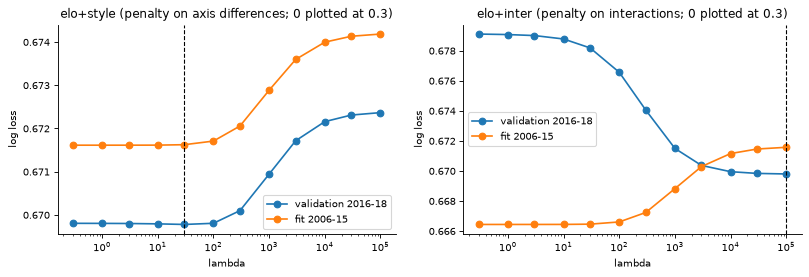

elo        unregularized: train log loss 0.6734, test 0.6685
elo+style  unregularized: train log loss 0.6706, test 0.6677
elo+inter  unregularized: train log loss 0.6688, test 0.6700


In [7]:
r = res[3]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for a, m in zip(axes, ["elo+style", "elo+inter"]):
    t = r["tuning"][m]
    x = np.where(t.index == 0, 0.3, t.index)
    a.semilogx(x, t["val_log_loss"], marker="o", label="validation 2016-18")
    a.semilogx(x, t["fit_log_loss"], marker="o", label="fit 2006-15")
    a.axvline(r["fits"][m]["lambda"] if r["fits"][m]["lambda"] > 0 else 0.3, color="k", ls="--", lw=1)
    a.set_title(f"{m} (penalty on {'axis differences' if m == 'elo+style' else 'interactions'}; 0 plotted at 0.3)")
    a.set_xlabel("lambda"); a.set_ylabel("log loss"); a.legend()
plt.show()
tr, te = r["train"], r["test"]
for m in M.MODELS:
    X, _, _ = M.design(tr, m); Xt, _, _ = M.design(te, m)
    b = M.fit_logistic(X, tr["y"].to_numpy(), 0.0)
    print(f"{m:10s} unregularized: train log loss {M.log_loss(M.predict(X, b), tr['y'].to_numpy()).mean():.4f}, "
          f"test {M.log_loss(M.predict(Xt, b), te['y'].to_numpy()).mean():.4f}")

The unregularized interaction model fits the training fights best and the test fights **worst** (worse than Elo alone): it overfits.
Validation keeps improving as the interaction penalty grows, so the tuned model shrinks the interactions to essentially zero and
ends up identical to the axis-difference model.

## 4. Calibration (test set, ≥ 3 prior fights)

Predicted P(A wins), in 10 equal-count bins, against the observed win rate. A and B are randomly oriented, so predictions span both sides of 0.5.

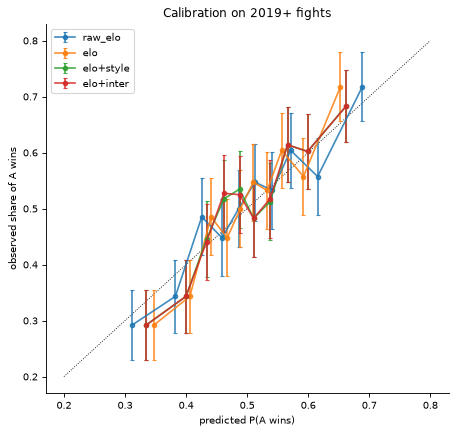

In [8]:
yt = res[3]["test"]["y"].to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0.2, 0.8], [0.2, 0.8], color="k", lw=0.8, ls=":")
for m in ["raw_elo"] + M.MODELS:
    p = res[3]["pred"][m]
    bins = pd.qcut(p, 10, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": yt}).groupby(bins, observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    se = np.sqrt(g["y"] * (1 - g["y"]) / g["n"])
    ax.errorbar(g["p"], g["y"], yerr=1.96 * se, marker="o", ms=4, capsize=2, label=m, alpha=0.85)
ax.set_xlabel("predicted P(A wins)"); ax.set_ylabel("observed share of A wins"); ax.set_title("Calibration on 2019+ fights")
ax.legend(); plt.show()

## 5. Style coefficients with confidence intervals

Logistic coefficients: the change in log-odds of A winning per 1 SD difference on an axis, or per unit of the interaction term.
Elo is per 100 points. Two views:

- **Fitted models (training period, tuned penalties):** the coefficients actually used for the test predictions, with bootstrap CIs
  (500 resamples of training fights, same penalties).
- **Replication check (no penalty):** the same specification estimated separately on the training period and on the test period.
  An effect "holds up" only if it has the same sign and a CI excluding 0 in both, **and** using it improves test predictions (section 3).

In [9]:
tr, te = res[3]["train"], res[3]["test"]
fits = res[3]["fits"]
tables = {}
for m in ["elo+style", "elo+inter"]:
    tables[m] = M.coefficient_cis(tr, m, fits[m]["penalty"].to_numpy(), n_boot=500).rename(index=NAMES)
    print(f"{m}: fitted on 2006-18 with the tuned penalties"); display(tables[m].round(3))
rep = pd.concat({"train 2006-18": M.coefficient_cis(tr, "elo+inter", 0.0, n_boot=500),
                 "test 2019+": M.coefficient_cis(te, "elo+inter", 0.0, n_boot=500)}, axis=1)
rep.index = [NAMES[i] for i in rep.index]
sig = lambda s: (s["lo"] > 0) | (s["hi"] < 0)
rep[("", "replicates")] = sig(rep["train 2006-18"]) & sig(rep["test 2019+"]) & (np.sign(rep[("train 2006-18", "estimate")]) == np.sign(rep[("test 2019+", "estimate")]))
print("Replication check, unpenalized elo + differences + interactions:"); display(rep.round(3))

elo+style: fitted on 2006-18 with the tuned penalties


,estimate,lo,hi
Elo difference (per 100 points),0.453,0.327,0.557
Δ grappler vs. volume striker,0.075,-0.001,0.146
Δ clinch and body work,-0.028,-0.097,0.038
Δ submission hunting,-0.076,-0.147,0.001
Δ leg kicking,-0.013,-0.076,0.054


elo+inter: fitted on 2006-18 with the tuned penalties


,estimate,lo,hi
Elo difference (per 100 points),0.453,0.327,0.557
Δ grappler vs. volume striker,0.075,-0.001,0.146
Δ clinch and body work,-0.028,-0.097,0.038
Δ submission hunting,-0.076,-0.147,0.001
Δ leg kicking,-0.013,-0.076,0.055
grappler vs. volume striker × clinch and body work,0.000,-0.000,0.001
grappler vs. volume striker × submission hunting,-0.000,-0.001,0.000
grappler vs. volume striker × leg kicking,-0.000,-0.001,0.000
clinch and body work × submission hunting,-0.000,-0.001,0.000
clinch and body work × leg kicking,-0.000,-0.001,0.000


Replication check, unpenalized elo + differences + interactions:


train 2006-18               test 2019+                         
                                                        estimate     lo     hi   estimate     lo     hi replicates
Elo difference (per 100 points)                            0.453  0.329  0.562      0.565  0.445  0.701       True
Δ grappler vs. volume striker                              0.079 -0.003  0.156      0.141  0.066  0.214      False
Δ clinch and body work                                    -0.036 -0.115  0.031      0.008 -0.058  0.081      False
Δ submission hunting                                      -0.079 -0.159  0.009      0.007 -0.063  0.080      False
Δ leg kicking                                             -0.005 -0.071  0.071      0.021 -0.044  0.087      False
grappler vs. volume striker × clinch and body work         0.052 -0.014  0.118      0.041 -0.029  0.111      False
grappler vs. volume striker × submission hunting          -0.021 -0.095  0.051     -0.011 -0.077  0.049      False
grappler vs. volume striker × leg kicking                 -0.040 -0.102  0.023      0.024 -0.044  0.092      False
clinch and body work × submission hunting                 -0.022 -0.097  0.042      0.008 -0.055  0.075      False
clinch and body work × leg kicking                        -0.035 -0.106  0.032     -0.068 -0.137 -0.003      False
submission hunting × leg kicking                          -0.031 -0.101  0.035      0.070  0.003  0.139      False

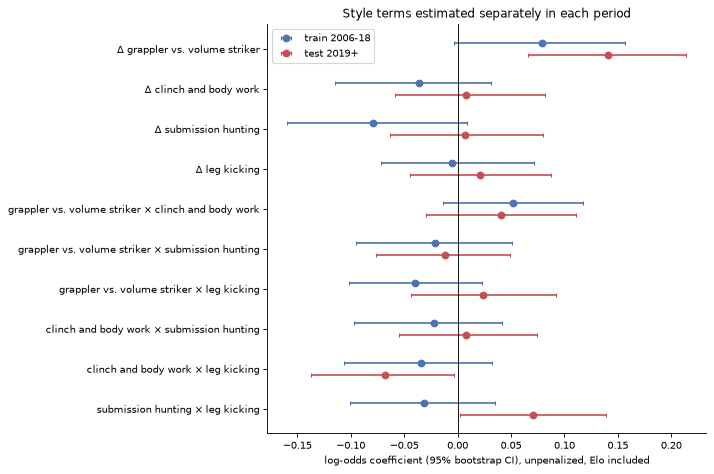

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
terms = [t for t in rep.index if not t.startswith("Elo")]
yy = np.arange(len(terms))
for k, (period, off, col) in enumerate([("train 2006-18", -0.15, "#4C72B0"), ("test 2019+", 0.15, "#C44E52")]):
    e = rep.loc[terms, (period, "estimate")]; lo = rep.loc[terms, (period, "lo")]; hi = rep.loc[terms, (period, "hi")]
    ax.errorbar(e, yy + off, xerr=[e - lo, hi - e], fmt="o", color=col, capsize=2, label=period)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy, terms); ax.invert_yaxis()
ax.set_xlabel("log-odds coefficient (95% bootstrap CI), unpenalized, Elo included")
ax.set_title("Style terms estimated separately in each period"); ax.legend()
plt.tight_layout(); plt.show()

## 6. The pre-specified grappling test

The only follow-up test, specified in `docs/matchups.md` and `matchups.GRAPPLING_TEST` before it was run. The measure is takedown
attempts per 15 minutes only (shrunk, era-relative z), with no control time or ground strikes. The model is improved Elo plus the
fighters' difference on this measure, trained on 2006–18 and tested on 2019+. It passes only if the whole 95% CI of Δ test log loss
is below 0.

In [11]:
for k, v in M.GRAPPLING_TEST.items():
    print(f"{k:16s} {v}")
gt = M.grappling_test(data)
print(f"\ntrain {gt['n_train']:,} fights, test {gt['n_test']:,} fights")
print(f"test log loss: Elo {gt['log_loss']['elo']:.4f}, Elo + takedown attempts {gt['log_loss']['elo+td']:.4f}")
print(f"Δ log loss {gt['d_log_loss']:+.4f}  95% CI [{gt['d_log_loss_ci'][0]:+.4f}, {gt['d_log_loss_ci'][1]:+.4f}]  ->  "
      f"{'PASSES: improves predictions' if gt['passes'] else 'does not pass: no demonstrated improvement'}")
print(f"Δ Brier    {gt['d_brier']:+.4f}  95% CI [{gt['d_brier_ci'][0]:+.4f}, {gt['d_brier_ci'][1]:+.4f}]")
display(pd.concat({"fitted on 2006-18": gt["coef_train"], "fitted on 2019+ (descriptive)": gt["coef_test"]}, axis=1).round(3))

measure          z_td_att_per15: shrunk takedown attempts per 15 min, era-relative z (no control time, no ground strikes)
feature          td_a - td_b (fighter A minus fighter B), from profiles as of the fight date
model            logistic, no intercept, unpenalized: improved Elo difference + takedown-attempt difference
baseline         logistic, no intercept: improved Elo difference only, fitted on the same fights
train            decisive fights 2006-01-01 to 2019-01-01, both fighters >= 3 prior UFC fights since 2000
test             decisive fights from 2019-01-01, same inclusion rule
primary_outcome  difference in mean test log loss (model - baseline), 95% paired bootstrap CI, 2,000 resamples, seed 0
pass_rule        the test improves predictions if the whole 95% CI is below 0
secondary        Brier difference; takedown coefficient with 95% CI fitted on train and, separately, on test (descriptive only)



train 1,772 fights, test 2,015 fights
test log loss: Elo 0.6685, Elo + takedown attempts 0.6658
Δ log loss -0.0027  95% CI [-0.0046, -0.0008]  ->  PASSES: improves predictions
Δ Brier    -0.0013  95% CI [-0.0022, -0.0004]


fitted on 2006-18               fitted on 2019+ (descriptive)              
                  estimate     lo     hi                      estimate     lo     hi
elo_diff             0.452  0.326  0.558                         0.576  0.457  0.706
d_td_att             0.068 -0.011  0.138                         0.121  0.053  0.190

## 7. What holds up, in plain language

**A better skill baseline helped; style axes still didn't.** The improved Elo was chosen on 2005–18 fights only. On 2019+ fights it is
clearly better than the baseline: log loss 0.670 vs 0.683, and the favourite wins 58.0% vs 55.6%. Against this stronger baseline:

- **The four style-axis differences don't improve predictions.** Δ test log loss −0.0009 (95% CI −0.0039 to +0.0021) with 3+ prior
  fights, and +0.0023 (−0.0024 to +0.0067) with 5+. The same conclusion as with the baseline Elo.
- **Matchup interactions still don't help.** Unregularized, they overfit (test log loss 0.6700 vs 0.6685 for Elo alone). Validation
  shrinks them to zero. Two are nominally significant in the 2019+ period only (clinch and body work × leg kicking, −0.07; submission
  hunting × leg kicking, +0.07). Neither is significant in 2006–18, and the second has the opposite sign there. With ten style terms,
  one or two nominal hits in one period is about what chance produces, so **no matchup effect is claimed**.
- **Axis 1 (grappler vs. volume striker)** stays where it was: positive in both periods (+0.08 in 2006–18, CI −0.003 to +0.156; +0.14
  in 2019+), but not established.

**The one pre-specified follow-up test passed, modestly.** The measure is the difference between fighters in takedown attempts per
15 minutes (shrunk, era-relative), with no control time or ground strikes. Adding it to the improved Elo lowered 2019+ log loss by
0.0027 (95% CI −0.0046 to −0.0008) and Brier by 0.0013 (CI −0.0022 to −0.0004). That meets the pre-specified rule.

- In plain terms: a fighter who attempts more takedowns than their opponent, relative to fighters of their division and era, wins
  slightly more often than their Elo rating predicts. With the coefficient learned on 2006–18 (+0.07 per SD), a 1 SD edge moves an even
  fight to about 51.7%. That's a small effect, about a fifth of the gain from improving Elo.
- It is a **main effect of grappling intent**, not a matchup effect. It doesn't say which style beats which.
- **Caveats.**
  - The test was specified *after* the earlier analysis had already shown a positive 2019+ coefficient for axis 1, which includes
    takedown attempts. The test set wasn't untouched by the reasoning that led to this hypothesis, so this is weaker confirmation than
    a test on new data.
  - The coefficient fitted on 2006–18 alone isn't significant (CI −0.011 to +0.138), so the evidence rests mostly on the test period.
  - Attempting takedowns can still partly reflect skill (fighters attempt more when they expect to succeed), even without control time.
- **Robustness:** swapping fighters gives exactly complementary predictions. The models ignore corner assignment, which carries
  information of its own (red wins about 57% of 2019+ decisive fights). A test on fights after 2026-08-08, once available, would be the
  clean replication.